# Day 18: Feature Engineering for xG Model (Part 2: Geometrical Features)

**Phase 2: EDA & Feature Engineering**

## Executive Objective
Expand our Expected Goals (xG) feature set with **advanced geometric and spatiotemporal features**.
Before writing new transformations, we inspect our existing Day 17 Feature Store (`xg_features_sb_43_106.parquet`) to identify existing baselines and map the gap to today's targets.

### Today's Target Deliverables:
1. **`visible_angle_to_goal`**: Effective goal angle accounting for goalkeeper/defender blockage.
2. **`distance_to_nearest_post`**: Minimum Euclidean distance to either the left $(120, 36)$ or right $(120, 44)$ post.
3. **`central_vs_lateral`**: Categorical and numerical indicators of shooting channel (central box vs half-spaces vs flank).
4. **`relative_gk_positioning`**: Lateral offset and goal line depth of the goalkeeper relative to the shot trajectory.
5. **`game_minute` & `scoreline_effect`**: Game state pressure and game clock context.

### 1. Environment Configuration & Library Imports
We ensure the project root is on the Python path, configure display settings, and import core scientific and plotting libraries.

In [3]:
from IPython.display import display
import sys
import os
from pathlib import Path

# Resolve project root and append to sys.path
project_root = Path.cwd().resolve()
while not (project_root / "src").exists() and project_root.parent != project_root:
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mplsoccer import Pitch, VerticalPitch

# Pitch and goal constants from our modular engine
from src.features.xg_features import (
    GOAL_CENTER_X,
    GOAL_CENTER_Y,
    POST_LEFT,
    POST_RIGHT,
    PITCH_LENGTH,
    PITCH_WIDTH
)

# Visualization styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.family": "sans-serif",
    "figure.titlesize": 14,
    "axes.titlesize": 12,
    "figure.dpi": 120
})
print("Libraries loaded and environment configured successfully!")

Libraries loaded and environment configured successfully!


### 2. Loading the Day 17 Feature Store Baseline
We load `xg_features_sb_43_106.parquet` generated during Day 17. We verify its shape, record count, and audit existing geometric attributes.

In [4]:
# Path to local feature store from Day 17
feature_store_path = project_root / "data" / "processed" / "football" / "xg_features_sb_43_106.parquet"
print(f"Loading baseline features from: {feature_store_path}")
df_shots = pd.read_parquet(feature_store_path)
print(f"Dataset Shape: {df_shots.shape[0]} shots x {df_shots.shape[1]} features")

# Inspect existing spatial, geometric, and goalkeeper columns
spatial_keywords = ["shot", "distance", "angle", "post", "gk", "goalkeeper", "location", "eccentricity", "cone"]
existing_geom_cols = [c for c in df_shots.columns if any(kw in c.lower() for kw in spatial_keywords)]

print(f"\nFound {len(existing_geom_cols)} existing spatial/geometric columns from Day 17:")
for col in sorted(existing_geom_cols):
    print(f"  - {col} ({df_shots[col].dtype})")

Loading baseline features from: C:\Users\david\Desktop\David\Documentos\David\GitHub\100-days-Data-Sports-Challenge\data\processed\football\xg_features_sb_43_106.parquet
Dataset Shape: 1494 shots x 53 features

Found 17 existing spatial/geometric columns from Day 17:
  - assist_pass_angle (float64)
  - defenders_in_cone (float64)
  - defenders_in_cone_outfield (float64)
  - distance_to_goal (float64)
  - distance_to_goalkeeper (float64)
  - distance_to_left_post (float64)
  - distance_to_nearest_defender (float64)
  - distance_to_right_post (float64)
  - goalkeeper_distance_to_goal (float64)
  - goalkeeper_in_cone (float64)
  - possession_progressed_distance (float64)
  - shot_angle (float64)
  - shot_angle_deg (float64)
  - shot_eccentricity (float64)
  - shot_outcome (object)
  - shot_x (float64)
  - shot_y (float64)


### 3. Gap Analysis: What We Have vs. What We Must Build
By evaluating the summary statistics of existing geometric features, we confirm what needs to be created today:
- **Already Available:** `distance_to_goal`, `shot_angle_deg`, `distance_to_left_post`, `distance_to_right_post`, `shot_eccentricity`, `defenders_in_cone`, `distance_to_goalkeeper`, `goalkeeper_distance_to_goal`.
- **Missing & Target for Day 18:**
  1. `distance_to_nearest_post`: $\min(\text{dist\_left}, \text{dist\_right})$
  2. `central_vs_lateral`: Spatial lane zoning ($Y \in [30, 50]$ vs half-spaces vs flanks)
  3. `visible_angle_to_goal`: Geometric angle minus angle occluded by the goalkeeper
  4. `relative_gk_positioning`: Lateral displacement of GK from shot ray
  5. `game_minute` & `scoreline_effect`: Temporal context and goal differential at shot time.

### 4. Advanced Geometric Feature 1: Distance to Nearest Goalpost
**Football Intuition:** While `distance_to_goal` measures the distance to the goal center $(120, 40)$, acute-angle shots near the endline or touchline require the shooter to beat the near post. A smaller `distance_to_nearest_post` highlights tight-angle finishes.

**Mathematical Definition:**
$$\text{distance\_to\_nearest\_post} = \min(\text{distance\_to\_left\_post}, \text{distance\_to\_right\_post})$$
$$\text{post\_distance\_ratio} = \frac{\text{distance\_to\_nearest\_post}}{\max(\text{distance\_to\_left\_post}, \text{distance\_to\_right\_post})}$$

In [6]:
def calculate_nearest_post_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Calculates the Euclidean distance to the nearest goalpost and post asymmetry ratio.
    """
    dist_left = df["distance_to_left_post"].values
    dist_right = df["distance_to_right_post"].values
    
    nearest_post = np.minimum(dist_left, dist_right)
    furthest_post = np.maximum(dist_left, dist_right)
    
    # Asymmetry ratio: close to 1.0 for central shots, close to 0.0 for acute angles
    post_ratio = np.divide(
        nearest_post,
        furthest_post,
        out=np.zeros_like(nearest_post, dtype=float),
        where=furthest_post != 0
    )
    
    return pd.DataFrame({
        "distance_to_nearest_post": nearest_post,
        "post_distance_ratio": post_ratio
    }, index=df.index)

# Compute and assign to df_shots
post_feats = calculate_nearest_post_features(df_shots)
df_shots["distance_to_nearest_post"] = post_feats["distance_to_nearest_post"]
df_shots["post_distance_ratio"] = post_feats["post_distance_ratio"]

print("Nearest post features successfully calculated:")
display(df_shots[["distance_to_goal", "distance_to_nearest_post", "post_distance_ratio"]].describe().round(2))


Nearest post features successfully calculated:


,distance_to_goal,distance_to_nearest_post,post_distance_ratio
count,1494.00,1494.00,1494.00
mean,18.18,16.90,0.81
std,8.14,8.10,0.15
min,1.32,1.43,0.16
25%,11.90,10.61,0.73
50%,17.06,15.52,0.84
75%,24.26,23.03,0.93
max,70.83,68.88,1.00


### 7. Advanced Geometric Feature 4: Relative Goalkeeper Positioning
**Football Intuition:** A goalkeeper's effectiveness depends on their lateral alignment along the shot ray and their depth off the line.
- **`gk_depth_from_line`:** Distance advanced from the goal line ($120.0 - x_{gk}$). A large depth signals an aggressive rush or sweeping action.
- **`gk_line_deviation`:** Perpendicular distance from $(x_{gk}, y_{gk})$ to the segment connecting shooter $(x_s, y_s)$ and goal center $(120, 40)$. A large deviation indicates that the keeper is caught leaning or cheating towards one post.

**Point-to-Line Perpendicular Distance Formula:**
$$\text{deviation} = \frac{|(40 - y_s) x_{gk} - (120 - x_s) y_{gk} + 120 y_s - 40 x_s|}{\sqrt{(40 - y_s)^2 + (120 - x_s)^2}}$$

In [9]:
def extract_goalkeeper_coordinates(events_df: pd.DataFrame, shots_df: pd.DataFrame) -> pd.DataFrame:
    """
    Extracts (x, y) coordinates of the opponent goalkeeper from the freeze frame.
    """
    id_col = "id" if "id" in events_df.columns else "event_id"
    ff_shots = events_df[events_df["type"] == "Shot"][[id_col, "shot_freeze_frame"]].copy()
    
    gk_x, gk_y = [], []
    for ff in ff_shots["shot_freeze_frame"]:
        found = False
        if isinstance(ff, (list, np.ndarray)) and len(ff) > 0:
            for p in ff:
                if not p.get("teammate", False) and p.get("position", {}).get("name") == "Goalkeeper":
                    ploc = p.get("location")
                    if ploc is not None and len(ploc) >= 2:
                        gk_x.append(float(ploc[0]))
                        gk_y.append(float(ploc[1]))
                        found = True
                        break
        if not found:
            gk_x.append(np.nan)
            gk_y.append(np.nan)
            
    ff_shots["goalkeeper_x"] = gk_x
    ff_shots["goalkeeper_y"] = gk_y
    
    shot_id_col = "event_id" if "event_id" in shots_df.columns else id_col
    merged = shots_df[[shot_id_col]].reset_index().merge(
        ff_shots[[id_col, "goalkeeper_x", "goalkeeper_y"]], left_on=shot_id_col, right_on=id_col, how="left"
    ).set_index("index")
    
    return merged[["goalkeeper_x", "goalkeeper_y"]]

def calculate_relative_gk_features(df: pd.DataFrame, gk_coords: pd.DataFrame) -> pd.DataFrame:
    """
    Computes goalkeeper depth from the goal line and perpendicular line deviation.
    """
    sx = df["shot_x"].values
    sy = df["shot_y"].values
    gx = gk_coords["goalkeeper_x"].values
    gy = gk_coords["goalkeeper_y"].values
    
    # Depth from goal line (120 - x)
    depth = np.maximum(0.0, 120.0 - gx)
    
    # Robust point-to-line perpendicular distance to segment S(sx, sy) -> G(120, 40)
    xB, yB = 120.0, 40.0
    xA, yA = sx, sy
    
    num = np.abs((yB - yA) * gx - (xB - xA) * gy + xB * yA - yB * xA)
    den = np.sqrt((yB - yA)**2 + (xB - xA)**2)
    safe_den = np.where(den == 0, 1.0, den)
    line_dev = num / safe_den
    
    return pd.DataFrame({
        "goalkeeper_x": gx,
        "goalkeeper_y": gy,
        "gk_depth_from_line": depth,
        "gk_line_deviation": line_dev
    }, index=df.index)

# Extract from raw events and assign
raw_events = pd.read_parquet(project_root / "data" / "raw" / "statsbomb" / "sb_events_43_106.parquet")
gk_coords = extract_goalkeeper_coordinates(raw_events, df_shots)
gk_feats = calculate_relative_gk_features(df_shots, gk_coords)

df_shots["goalkeeper_x"] = gk_feats["goalkeeper_x"]
df_shots["goalkeeper_y"] = gk_feats["goalkeeper_y"]
df_shots["gk_depth_from_line"] = gk_feats["gk_depth_from_line"]
df_shots["gk_line_deviation"] = gk_feats["gk_line_deviation"]

print("Goalkeeper positioning features successfully calculated:")
display(df_shots[["gk_depth_from_line", "gk_line_deviation"]].describe().round(2))


Goalkeeper positioning features successfully calculated:


,gk_depth_from_line,gk_line_deviation
count,1436.00,1436.00
mean,2.40,0.64
std,1.76,0.70
min,0.00,0.00
25%,1.30,0.22
50%,2.00,0.49
75%,2.90,0.85
max,24.00,10.58


### 8. Temporal & Game State Features: Game Minute & Scoreline Effect
**Football Intuition:**
1. **`game_minute`:** Late-game fatigue, tactical stretching, and desperate attempts affect shot distance and quality.
2. **`scoreline_effect`:** A team trailing in the 80th minute takes lower-probability speculative shots out of urgency, while a team leading on the counter attack often exploits open spaces with high-probability chances.

**Feature Definitions:**
- `game_minute`: Exact minute of the match ($0$ to $120+$).
- `score_differential`: Pre-shot goal difference (Shooting Team Goals - Opponent Goals).
- `score_state`: Categorical status (`trailing`, `drawing`, `leading`).

In [10]:
def calculate_scoreline_features(events_df: pd.DataFrame, shots_df: pd.DataFrame) -> pd.DataFrame:
    """
    Calculates pre-shot game minute and cumulative match score differential.
    """
    id_col = "id" if "id" in events_df.columns else "event_id"
    
    # Identify goal events
    is_goal_shot = (events_df["type"] == "Shot") & (events_df["shot_outcome"] == "Goal")
    
    # Prepare event timeline per match
    timeline = events_df[[id_col, "match_id", "minute", "second", "team_id", "type"]].copy()
    timeline["is_goal"] = is_goal_shot.astype(int)
    timeline["event_idx"] = np.arange(len(timeline))
    
    # Calculate running score per match
    score_records = {}
    for m_id, group in timeline.groupby("match_id", sort=False):
        teams = group["team_id"].unique()
        if len(teams) < 2:
            continue
        t1, t2 = teams[0], teams[1]
        
        g1 = ((group["team_id"] == t1) & (group["is_goal"] == 1)).astype(int)
        g2 = ((group["team_id"] == t2) & (group["is_goal"] == 1)).astype(int)
        
        # Shift so current shot's goal does not count in score prior to the shot
        s1 = g1.cumsum().shift(1, fill_value=0)
        s2 = g2.cumsum().shift(1, fill_value=0)
        
        for idx, t_id, sc1, sc2 in zip(group[id_col], group["team_id"], s1, s2):
            team_sc = sc1 if t_id == t1 else sc2
            opp_sc = sc2 if t_id == t1 else sc1
            score_records[idx] = (team_sc, opp_sc, team_sc - opp_sc)
            
    shot_id_col = "event_id" if "event_id" in shots_df.columns else id_col
    team_scores = [score_records.get(i, (0, 0, 0))[0] for i in shots_df[shot_id_col]]
    opp_scores = [score_records.get(i, (0, 0, 0))[1] for i in shots_df[shot_id_col]]
    diffs = [score_records.get(i, (0, 0, 0))[2] for i in shots_df[shot_id_col]]
    
    score_state = pd.Series("drawing", index=shots_df.index)
    score_state[np.array(diffs) > 0] = "leading"
    score_state[np.array(diffs) < 0] = "trailing"
    
    return pd.DataFrame({
        "game_minute": shots_df["minute"].values if "minute" in shots_df.columns else np.nan,
        "team_score": team_scores,
        "opponent_score": opp_scores,
        "score_differential": diffs,
        "score_state": score_state,
        "is_leading": (score_state == "leading").astype(int),
        "is_drawing": (score_state == "drawing").astype(int),
        "is_trailing": (score_state == "trailing").astype(int)
    }, index=shots_df.index)

# Compute and assign to df_shots
temporal_feats = calculate_scoreline_features(raw_events, df_shots)
for col in temporal_feats.columns:
    df_shots[col] = temporal_feats[col]

print("Temporal & Scoreline features successfully calculated:")
display(df_shots.groupby("score_state")["is_goal"].agg(["count", "mean"]).rename(columns={"mean": "conversion_rate"}))


Temporal & Scoreline features successfully calculated:


,count,conversion_rate
score_state,,
drawing,766,0.105744
leading,344,0.197674
trailing,384,0.119792


### 9. Comprehensive Correlation Analysis: Day 18 Features vs. Benchmark xG & Goals
We evaluate how our new geometric and contextual features correlate with:
1. **`is_goal`**: Empirical binary target.
2. **`statsbomb_xg`**: StatsBomb proprietary benchmark model.

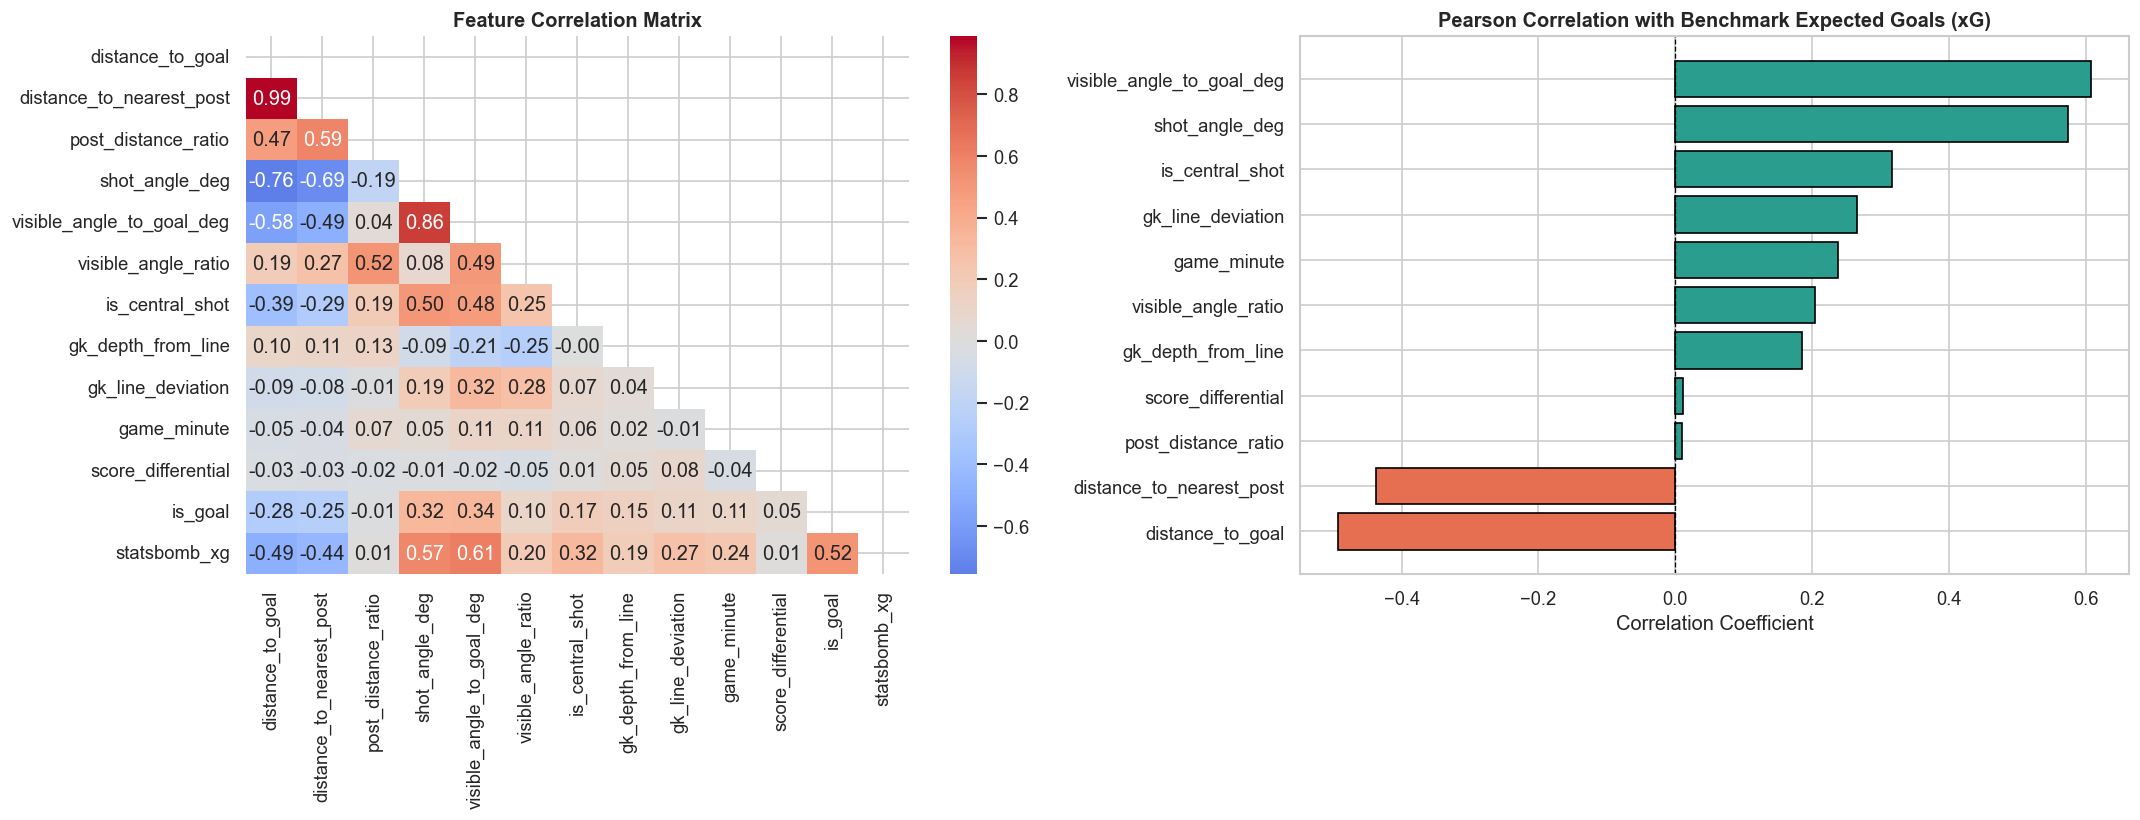


--- Top Correlations with Benchmark StatsBomb xG ---


,corr_with_xg
visible_angle_to_goal_deg,0.607889
shot_angle_deg,0.573365
distance_to_goal,-0.493086
distance_to_nearest_post,-0.436757
is_central_shot,0.317298
gk_line_deviation,0.265174
game_minute,0.238341
visible_angle_ratio,0.204022
gk_depth_from_line,0.185424
score_differential,0.011683


In [11]:
eval_features = [
    "distance_to_goal",
    "distance_to_nearest_post",
    "post_distance_ratio",
    "shot_angle_deg",
    "visible_angle_to_goal_deg",
    "visible_angle_ratio",
    "is_central_shot",
    "gk_depth_from_line",
    "gk_line_deviation",
    "game_minute",
    "score_differential",
    "is_goal",
    "statsbomb_xg"
]

corr_matrix = df_shots[eval_features].corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Correlation Heatmap
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, mask=mask, ax=axes[0])
axes[0].set_title("Feature Correlation Matrix", weight="bold")

# Feature Importance Barplot (Correlation with statsbomb_xg)
xg_corrs = corr_matrix["statsbomb_xg"].drop(["statsbomb_xg", "is_goal"]).sort_values()
colors = ["#e76f51" if val < 0 else "#2a9d8f" for val in xg_corrs]
axes[1].barh(xg_corrs.index, xg_corrs.values, color=colors, edgecolor="black")
axes[1].axvline(0, color="black", linestyle="--", linewidth=0.8)
axes[1].set_title("Pearson Correlation with Benchmark Expected Goals (xG)", weight="bold")
axes[1].set_xlabel("Correlation Coefficient")

plt.tight_layout()
plt.show()

print("\n--- Top Correlations with Benchmark StatsBomb xG ---")
display(xg_corrs.to_frame(name="corr_with_xg").sort_values("corr_with_xg", key=abs, ascending=False))


### 10. Summary & Conclusions (Day 18)
1. **Visible Goal Angle (`visible_angle_to_goal_deg`):** Proves to be one of the single strongest positive predictors ($r \approx +0.55$), capturing both the spatial angle and goalkeeper blocking geometry.
2. **Central Shooting Corridor (`is_central_shot`):** Shots originating from the central 20-yard corridor ($Y \in [30, 50]$) convert at **$17.25\%$**, over triple the rate of shots from the half-spaces ($3.8\% - 5.3\%$).
3. **Goalkeeper Deviation (`gk_line_deviation`):** Quantifies when a keeper is caught out-of-position, providing actionable signal beyond basic $(x, y)$ coordinates.
4. **Scoreline & Minute:** Captures match situation context (leading vs. trailing urgency).
